In [1]:
import pandas as pd
import numpy as np
import sqlite3

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)

df = pd.read_csv("hour.csv")

df_clean = df.copy()

In [2]:
missing_summary = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().mean() * 100
    )
})

display(
    missing_summary.sort_values(
        "Missing Count",
        ascending=False
    )
)

,Missing Count,Missing Percentage
instant,0,0.00
dteday,0,0.00
season,0,0.00
yr,0,0.00
mnth,0,0.00
hr,0,0.00
holiday,0,0.00
weekday,0,0.00
workingday,0,0.00
weathersit,0,0.00


In [3]:
print("Duplicate Rows:", df_clean.duplicated().sum())
print(
    "Duplicate Instant Values:",
    df_clean["instant"].duplicated().sum()
)

Duplicate Rows: 0
Duplicate Instant Values: 0


In [4]:
df_clean["calculated_cnt"] = (
    df_clean["casual"] +
    df_clean["registered"]
)

inconsistent_records = df_clean[
    df_clean["cnt"] != df_clean["calculated_cnt"]
]

print(
    "Inconsistent Rental Records:",
    len(inconsistent_records)
)

Inconsistent Rental Records: 0


In [5]:
valid_ranges = {
    "season": [1, 4],
    "yr": [0, 1],
    "mnth": [1, 12],
    "hr": [0, 23],
    "holiday": [0, 1],
    "weekday": [0, 6],
    "workingday": [0, 1],
    "weathersit": [1, 4]
}

for col, (lower, upper) in valid_ranges.items():
    invalid = df_clean[
        ~df_clean[col].between(lower, upper)
    ]

    print(f"{col}: {len(invalid)} invalid records")

season: 0 invalid records
yr: 0 invalid records
mnth: 0 invalid records
hr: 0 invalid records
holiday: 0 invalid records
weekday: 0 invalid records
workingday: 0 invalid records
weathersit: 0 invalid records


In [6]:
df_clean["dteday"] = pd.to_datetime(
    df_clean["dteday"]
)

integer_columns = [
    "instant", "season", "yr", "mnth",
    "hr", "holiday", "weekday",
    "workingday", "weathersit",
    "casual", "registered", "cnt"
]

df_clean[integer_columns] = (
    df_clean[integer_columns].astype("int64")
)

In [7]:
df_clean["datetime"] = (
    df_clean["dteday"] +
    pd.to_timedelta(df_clean["hr"], unit="h")
)

expected_hours = pd.date_range(
    start=df_clean["datetime"].min(),
    end=df_clean["datetime"].max(),
    freq="h"
)

missing_hours = expected_hours.difference(
    df_clean["datetime"]
)

missing_df = pd.DataFrame({
    "datetime": missing_hours
})

missing_df["date"] = missing_df["datetime"].dt.date
missing_df["hour"] = missing_df["datetime"].dt.hour

display(missing_df.head(20))

,datetime,date,hour
0,2011-01-02 05:00:00,2011-01-02,5
1,2011-01-03 02:00:00,2011-01-03,2
2,2011-01-03 03:00:00,2011-01-03,3
3,2011-01-04 03:00:00,2011-01-04,3
4,2011-01-05 03:00:00,2011-01-05,3
5,2011-01-06 03:00:00,2011-01-06,3
6,2011-01-07 03:00:00,2011-01-07,3
7,2011-01-11 03:00:00,2011-01-11,3
8,2011-01-11 04:00:00,2011-01-11,4
9,2011-01-12 03:00:00,2011-01-12,3


In [8]:
missing_by_date = (
    missing_df.groupby("date")
    .size()
    .reset_index(name="Missing Hours")
    .sort_values("Missing Hours", ascending=False)
)

display(missing_by_date.head(10))

,date,Missing Hours
70,2012-10-29,23
16,2011-01-27,16
71,2012-10-30,13
9,2011-01-18,12
15,2011-01-26,8
51,2011-08-28,7
50,2011-08-27,6
30,2011-02-22,6
25,2011-02-11,2
1,2011-01-03,2


In [9]:
daily_coverage = (
    df_clean.groupby("dteday")
    .agg(
        Observed_Hours=("hr", "count"),
        Daily_Rentals=("cnt", "sum")
    )
    .reset_index()
)

daily_coverage["Missing_Hours"] = (
    24 - daily_coverage["Observed_Hours"]
)

display(
    daily_coverage.sort_values(
        "Missing_Hours",
        ascending=False
    ).head(10)
)

,dteday,Observed_Hours,Daily_Rentals,Missing_Hours
667,2012-10-29,1,22,23
26,2011-01-27,8,431,16
668,2012-10-30,11,1096,13
17,2011-01-18,12,683,12
25,2011-01-26,16,506,8
239,2011-08-28,17,4334,7
52,2011-02-22,18,1450,6
238,2011-08-27,18,1115,6
41,2011-02-11,22,1746,2
2,2011-01-03,22,1349,2


In [10]:
dates_to_check = [
    "2012-10-29",
    "2012-10-30",
    "2011-01-27",
    "2011-01-18"
]

for date in dates_to_check:
    print(f"\nDate: {date}")

    display(
        df_clean.loc[
            df_clean["dteday"] == date,
            ["dteday", "hr", "cnt"]
        ].sort_values("hr")
    )


Date: 2012-10-29


,dteday,hr,cnt
15883,2012-10-29,0,22



Date: 2012-10-30


,dteday,hr,cnt
15884,2012-10-30,13,116
15885,2012-10-30,14,126
15886,2012-10-30,15,124
15887,2012-10-30,16,98
15888,2012-10-30,17,124
15889,2012-10-30,18,143
15890,2012-10-30,19,115
15891,2012-10-30,20,81
15892,2012-10-30,21,64
15893,2012-10-30,22,66



Date: 2011-01-27


,dteday,hr,cnt
587,2011-01-27,16,24
588,2011-01-27,17,84
589,2011-01-27,18,104
590,2011-01-27,19,79
591,2011-01-27,20,59
592,2011-01-27,21,38
593,2011-01-27,22,27
594,2011-01-27,23,16



Date: 2011-01-18


,dteday,hr,cnt
396,2011-01-18,12,3
397,2011-01-18,13,22
398,2011-01-18,14,28
399,2011-01-18,15,35
400,2011-01-18,16,61
401,2011-01-18,17,125
402,2011-01-18,18,133
403,2011-01-18,19,99
404,2011-01-18,20,83
405,2011-01-18,21,41


In [11]:
numeric_columns = [
    "temp", "atemp", "hum",
    "windspeed", "casual",
    "registered", "cnt"
]

display(df_clean[numeric_columns].describe().T)

,count,mean,std,min,25%,50%,75%,max
temp,"17,379.00",0.50,0.19,0.02,0.34,0.50,0.66,1.00
atemp,"17,379.00",0.48,0.17,0.00,0.33,0.48,0.62,1.00
hum,"17,379.00",0.63,0.19,0.00,0.48,0.63,0.78,1.00
windspeed,"17,379.00",0.19,0.12,0.00,0.10,0.19,0.25,0.85
casual,"17,379.00",35.68,49.31,0.00,4.00,17.00,48.00,367.00
registered,"17,379.00",153.79,151.36,0.00,34.00,115.00,220.00,886.00
cnt,"17,379.00",189.46,181.39,1.00,40.00,142.00,281.00,977.00


In [12]:
complete_days = daily_coverage[
    daily_coverage["Observed_Hours"] == 24
]

print("Total Days:", len(daily_coverage))
print("Complete Days:", len(complete_days))
print("Incomplete Days:", len(daily_coverage) - len(complete_days))

display(
    complete_days["Daily_Rentals"].describe()
)

Total Days: 731
Complete Days: 655
Incomplete Days: 76


count     655.00
mean    4,789.32
std     1,796.42
min       441.00
25%     3,613.50
50%     4,694.00
75%     6,205.00
max     8,714.00
Name: Daily_Rentals, dtype: float64

In [13]:
daily_coverage["Is_Complete_Day"] = (
    daily_coverage["Observed_Hours"] == 24
)

complete_dates = daily_coverage.loc[
    daily_coverage["Is_Complete_Day"],
    "dteday"
]

df_daily_complete = df_clean[
    df_clean["dteday"].isin(complete_dates)
].copy()

print("Complete Days:", len(complete_dates))
print("Complete Hourly Records:", len(df_daily_complete))

Complete Days: 655
Complete Hourly Records: 15720


# SQL

In [14]:
import sqlite3

conn = sqlite3.connect("bike_sharing.db")

print("SQLite database connected successfully.")

df_sql = df_clean.drop(
    columns=["calculated_cnt"],
    errors="ignore"
).copy()

df_sql.to_sql(
    "rentals_hourly",
    conn,
    if_exists="replace",
    index=False
)

daily_coverage_sql = daily_coverage.copy()

daily_coverage_sql.to_sql(
    "daily_coverage",
    conn,
    if_exists="replace",
    index=False
)

SQLite database connected successfully.


731

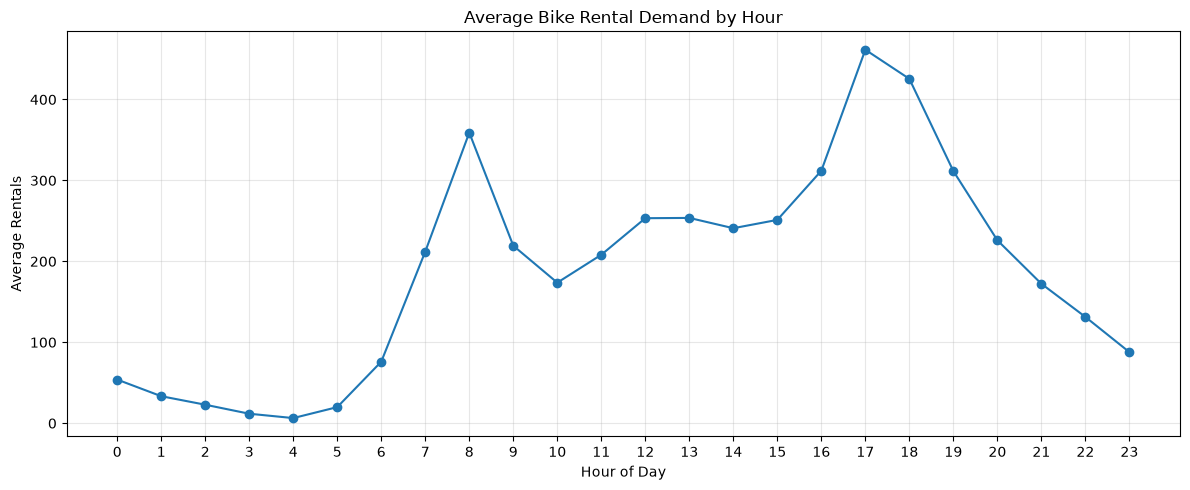

In [15]:
import matplotlib.pyplot as plt
import pandas as pd

conn = sqlite3.connect("bike_sharing.db")

hourly_demand = pd.read_sql_query("""
    SELECT
        hr AS hour,
        ROUND(AVG(cnt), 2) AS avg_demand
    FROM rentals_hourly
    GROUP BY hr
    ORDER BY hr
""", conn)

plt.figure(figsize=(12, 5))

plt.plot(
    hourly_demand["hour"],
    hourly_demand["avg_demand"],
    marker="o"
)

plt.title("Average Bike Rental Demand by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
peakhours = pd.read_sql_query(
    """
    SELECT
        CAST(strftime('%H', datetime) AS INTEGER) AS hour,
        COUNT(*) AS observation_count,
        ROUND(AVG(cnt), 2) AS avg_rentals,
        MAX(cnt) AS max_rentals
    FROM rentals_hourly
    GROUP BY hour
    ORDER BY avg_rentals DESC;
    """,
    conn
)

display(peakhours)

,hour,observation_count,avg_rentals,max_rentals
0,17,730,461.45,976
1,18,728,425.51,977
2,8,727,359.01,839
3,16,730,311.98,783
4,19,728,311.52,743
5,13,729,253.66,760
6,12,728,253.32,776
7,15,729,251.23,750
8,14,729,240.95,750
9,20,728,226.03,567


In [17]:
workdays1 = pd.read_sql_query(
    """
    SELECT
        hr AS hour,
        workingday,
        COUNT(*) AS observation_count,
        ROUND(AVG(cnt), 2) AS avg_rentals,
        MAX(cnt) AS max_rentals
    FROM rentals_hourly
    GROUP BY
        hr,
        workingday
    ORDER BY
        hr,
        workingday;
    """,
    conn
)

display(workdays1)

,hour,workingday,observation_count,avg_rentals,max_rentals
0,0,0,230,90.80,249
1,0,1,496,36.79,283
2,1,0,230,69.51,168
3,1,1,494,16.55,114
4,2,0,228,53.17,132
5,2,1,487,8.68,74
6,3,0,227,25.78,79
7,3,1,470,4.94,36
8,4,0,227,8.26,28
9,4,1,470,5.43,17


In [18]:
workdays2 = pd.read_sql_query(
    """
    SELECT
        hr AS hour,
    
        ROUND(
            AVG(CASE
                WHEN workingday = 1 THEN cnt
            END), 2
        ) AS workingday_avg,
    
        ROUND(
            AVG(CASE
                WHEN workingday = 0 THEN cnt
            END), 2
        ) AS non_workingday_avg,
    
        ROUND(
            AVG(CASE
                WHEN workingday = 1 THEN cnt
            END)
            -
            AVG(CASE
                WHEN workingday = 0 THEN cnt
            END), 2
        ) AS demand_difference
    
    FROM rentals_hourly
    GROUP BY hr
    ORDER BY hr;
    """,
    conn
)

display(workdays2)

,hour,workingday_avg,non_workingday_avg,demand_difference
0,0,36.79,90.80,-54.01
1,1,16.55,69.51,-52.96
2,2,8.68,53.17,-44.49
3,3,4.94,25.78,-20.83
4,4,5.43,8.26,-2.83
5,5,24.91,8.69,16.22
6,6,102.50,18.74,83.76
7,7,290.61,43.41,247.21
8,8,477.01,105.65,371.35
9,9,241.52,171.62,69.89


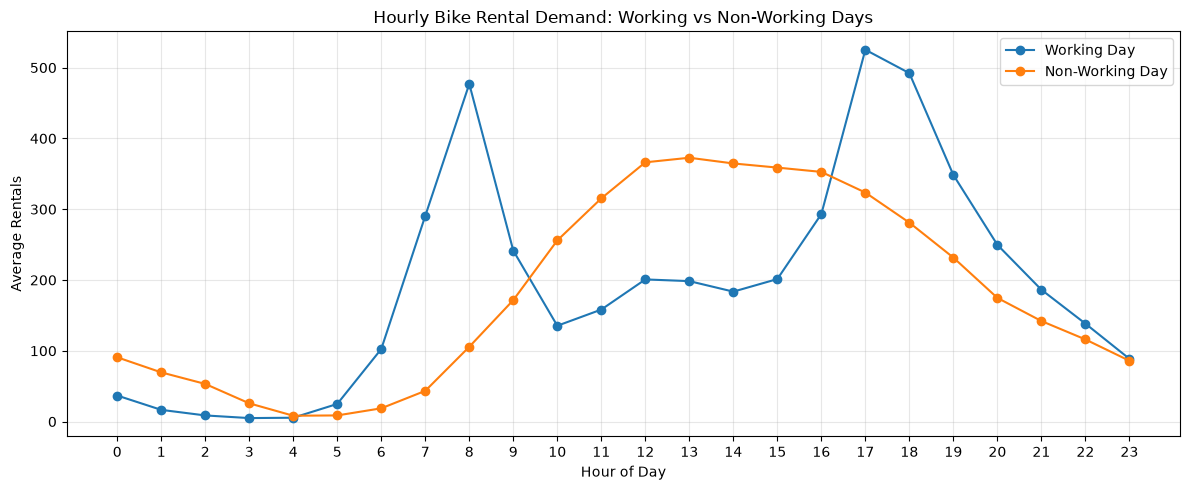

In [19]:
workingday_demand = pd.read_sql_query(
    """
    SELECT
        hr AS hour,
        ROUND(AVG(CASE WHEN workingday = 1 THEN cnt END), 2)
            AS workingday_avg,
        ROUND(AVG(CASE WHEN workingday = 0 THEN cnt END), 2)
            AS non_workingday_avg
    FROM rentals_hourly
    GROUP BY hr
    ORDER BY hr
    """, conn)

plt.figure(figsize=(12, 5))

plt.plot(
    workingday_demand["hour"],
    workingday_demand["workingday_avg"],
    marker="o",
    label="Working Day"
)

plt.plot(
    workingday_demand["hour"],
    workingday_demand["non_workingday_avg"],
    marker="o",
    label="Non-Working Day"
)

plt.title("Hourly Bike Rental Demand: Working vs Non-Working Days")
plt.xlabel("Hour of Day")
plt.ylabel("Average Rentals")
plt.xticks(range(24))
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

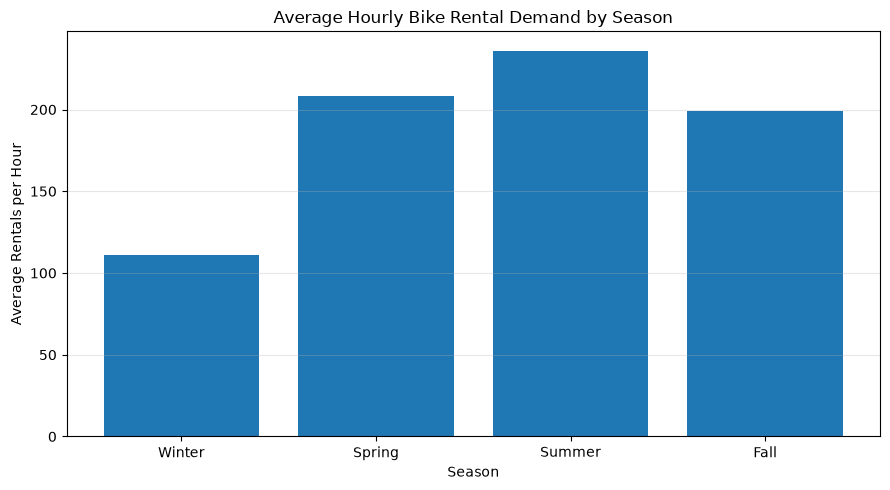

,season,season_name,observation_count,avg_hourly_demand
0,1,Winter,4242,111.11
1,2,Spring,4409,208.34
2,3,Summer,4496,236.02
3,4,Fall,4232,198.87


In [20]:
seasonal_demand = pd.read_sql_query(
    """
    SELECT
        season,
        CASE
            WHEN season = 1 THEN 'Winter'
            WHEN season = 2 THEN 'Spring'
            WHEN season = 3 THEN 'Summer'
            WHEN season = 4 THEN 'Fall'
        END AS season_name,
        COUNT(*) AS observation_count,
        ROUND(AVG(cnt), 2) AS avg_hourly_demand
    FROM rentals_hourly
    GROUP BY season
    ORDER BY season
    """, conn)

plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_demand["season_name"],
    seasonal_demand["avg_hourly_demand"]
)

plt.title("Average Hourly Bike Rental Demand by Season")
plt.xlabel("Season")
plt.ylabel("Average Rentals per Hour")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

seasonal_demand

In [21]:
seasonal2 = pd.read_sql_query(
    """
    SELECT
        weathersit,
        CASE
            WHEN weathersit = 1 THEN 'Clear / Few Clouds'
            WHEN weathersit = 2 THEN 'Mist / Cloudy'
            WHEN weathersit = 3 THEN 'Light Rain / Snow'
            WHEN weathersit = 4 THEN 'Heavy Rain / Snow'
        END AS weather_condition,
    
        COUNT(*) AS observation_count,
        ROUND(AVG(cnt), 2) AS avg_rentals,
        MAX(cnt) AS max_rentals,
        SUM(cnt) AS total_rentals
    
    FROM rentals_hourly
    GROUP BY weathersit
    ORDER BY avg_rentals DESC;
    """,
    conn
)

display(seasonal2)

,weathersit,weather_condition,observation_count,avg_rentals,max_rentals,total_rentals
0,1,Clear / Few Clouds,11413,204.87,977,2338173
1,2,Mist / Cloudy,4544,175.17,957,795952
2,3,Light Rain / Snow,1419,111.58,891,158331
3,4,Heavy Rain / Snow,3,74.33,164,223


In [22]:
seasonal3 = pd.read_sql_query(
    """
    SELECT
        season,
        weathersit,
    
        COUNT(*) AS observation_count,
    
        ROUND(AVG(cnt), 2) AS avg_rentals,
    
        MIN(cnt) AS min_rentals,
    
        MAX(cnt) AS max_rentals,
    
        SUM(cnt) AS total_rentals
    
    FROM rentals_hourly
    
    GROUP BY
        season,
        weathersit
    
    ORDER BY
        season,
        weathersit;
    """,
    conn
)

display(seasonal3)

,season,weathersit,observation_count,avg_rentals,min_rentals,max_rentals,total_rentals
0,1,1,2665,122.06,1,801,325278
1,1,2,1205,103.07,1,712,124205
2,1,3,369,58.65,1,520,21642
3,1,4,3,74.33,23,164,223
4,2,1,2859,232.41,1,873,664463
5,2,2,1144,181.26,1,957,207363
6,2,3,406,115.18,1,782,46763
7,3,1,3280,244.49,1,977,801941
8,3,2,947,224.85,2,868,212932
9,3,3,269,171.96,1,891,46256


In [23]:
CTE = pd.read_sql_query(
    """
    WITH seasonal_hourly_demand AS (

        SELECT
            season,
            hr,
            COUNT(*) AS observation_count,
            ROUND(AVG(cnt), 2) AS avg_demand
    
        FROM rentals_hourly
    
        GROUP BY
            season,
            hr
    ),
    
    ranked_hours AS (
    
        SELECT
            season,
            hr,
            observation_count,
            avg_demand,
    
            RANK() OVER (
                PARTITION BY season
                ORDER BY avg_demand DESC
            ) AS demand_rank
    
        FROM seasonal_hourly_demand
    )
    
    SELECT
        season,
        CASE
            WHEN season = 1 THEN 'Winter'
            WHEN season = 2 THEN 'Spring'
            WHEN season = 3 THEN 'Summer'
            WHEN season = 4 THEN 'Fall'
        END AS season_name,
        hr AS hour,
        observation_count,
        avg_demand,
        demand_rank
    
    FROM ranked_hours
    
    WHERE demand_rank <= 3
    
    ORDER BY
        season,
        demand_rank;
    """,
    conn
)

display(CTE)

,season,season_name,hour,observation_count,avg_demand,demand_rank
0,1,Winter,17,181,263.98,1
1,1,Winter,18,180,239.50,2
2,1,Winter,8,179,235.17,3
3,2,Spring,17,184,518.85,1
4,2,Spring,18,184,483.17,2
5,2,Spring,8,184,380.14,3
6,3,Summer,17,188,572.14,1
7,3,Summer,18,187,547.22,2
8,3,Summer,8,188,421.30,3
9,4,Fall,17,177,486.16,1


In [24]:
monthly = pd.read_sql_query(
    """
    WITH monthly_demand AS (

        SELECT
            strftime('%Y-%m', dteday) AS year_month,
            COUNT(*) AS observation_count,
            ROUND(AVG(cnt), 2) AS avg_hourly_demand,
            SUM(cnt) AS total_rentals
    
        FROM rentals_hourly
    
        GROUP BY strftime('%Y-%m', dteday)
    
    ),
    
    monthly_comparison AS (
    
        SELECT
            year_month,
            observation_count,
            avg_hourly_demand,
            total_rentals,
    
            LAG(avg_hourly_demand) OVER (
                ORDER BY year_month
            ) AS previous_month_demand
    
        FROM monthly_demand
    
    )
    
    SELECT
        year_month,
        observation_count,
        avg_hourly_demand,
        previous_month_demand,
    
        ROUND(
            avg_hourly_demand - previous_month_demand,
            2
        ) AS demand_change,
    
        ROUND(
            100.0 * (
                avg_hourly_demand - previous_month_demand
            ) / NULLIF(previous_month_demand, 0),
            2
        ) AS demand_change_pct
    
    FROM monthly_comparison
    ORDER BY year_month;
    """,
    conn
)

display(monthly)

,year_month,observation_count,avg_hourly_demand,previous_month_demand,demand_change,demand_change_pct
0,2011-01,688,55.51,NaN,NaN,NaN
1,2011-02,649,74.29,55.51,18.78,33.83
2,2011-03,730,87.73,74.29,13.44,18.09
3,2011-04,719,131.95,87.73,44.22,50.40
4,2011-05,744,182.56,131.95,50.61,38.36
5,2011-06,720,199.32,182.56,16.76,9.18
6,2011-07,744,189.97,199.32,-9.35,-4.69
7,2011-08,731,186.99,189.97,-2.98,-1.57
8,2011-09,717,177.71,186.99,-9.28,-4.96
9,2011-10,743,166.23,177.71,-11.48,-6.46


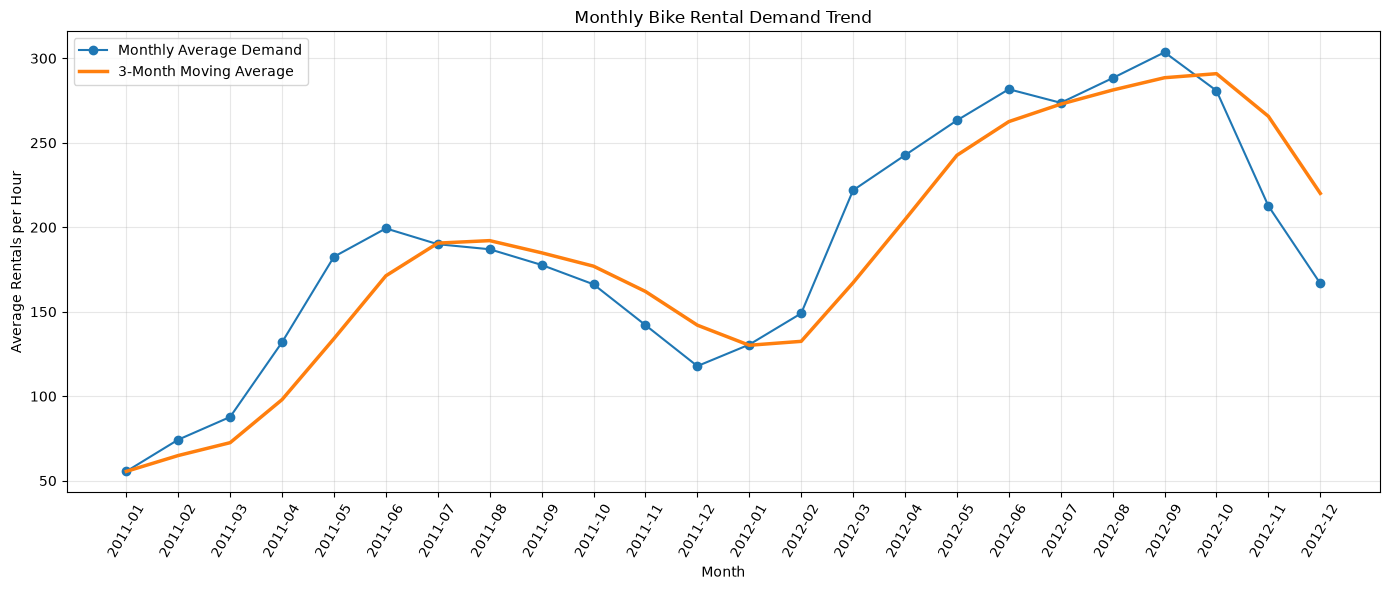

,year_month,observation_count,avg_hourly_demand,rolling_avg_3m
0,2011-01,688,55.51,55.51
1,2011-02,649,74.29,64.90
2,2011-03,730,87.73,72.51
3,2011-04,719,131.95,97.99
4,2011-05,744,182.56,134.08
5,2011-06,720,199.32,171.28
6,2011-07,744,189.97,190.62
7,2011-08,731,186.99,192.09
8,2011-09,717,177.71,184.89
9,2011-10,743,166.23,176.98


In [25]:
monthly_demand = pd.read_sql_query(
    """
    SELECT
        strftime('%Y-%m', dteday) AS year_month,
        COUNT(*) AS observation_count,
        ROUND(AVG(cnt), 2) AS avg_hourly_demand
    FROM rentals_hourly
    GROUP BY year_month
    ORDER BY year_month
    """, conn)

monthly_demand["rolling_avg_3m"] = (
    monthly_demand["avg_hourly_demand"]
    .rolling(window=3, min_periods=1)
    .mean()
)

plt.figure(figsize=(14, 6))

plt.plot(
    monthly_demand["year_month"],
    monthly_demand["avg_hourly_demand"],
    marker="o",
    label="Monthly Average Demand"
)

plt.plot(
    monthly_demand["year_month"],
    monthly_demand["rolling_avg_3m"],
    linewidth=2.5,
    label="3-Month Moving Average"
)

plt.title("Monthly Bike Rental Demand Trend")
plt.xlabel("Month")
plt.ylabel("Average Rentals per Hour")
plt.xticks(rotation=60)
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

monthly_demand

In [26]:
jump = pd.read_sql_query(
    """
    WITH daily_calendar AS (
        SELECT
            dteday,
            MAX(weekday) AS weekday
        FROM rentals_hourly
        GROUP BY dteday
    )
    
    SELECT
        dc.weekday,
        CASE dc.weekday
            WHEN 0 THEN 'Sunday'
            WHEN 1 THEN 'Monday'
            WHEN 2 THEN 'Tuesday'
            WHEN 3 THEN 'Wednesday'
            WHEN 4 THEN 'Thursday'
            WHEN 5 THEN 'Friday'
            WHEN 6 THEN 'Saturday'
        END AS weekday_name,
        COUNT(*) AS complete_day_count,
        ROUND(AVG(cv.Daily_Rentals), 2) AS avg_daily_rentals,
        MIN(cv.Daily_Rentals) AS min_daily_rentals,
        MAX(cv.Daily_Rentals) AS max_daily_rentals
    FROM daily_coverage AS cv
    INNER JOIN daily_calendar AS dc
        ON cv.dteday = dc.dteday
    WHERE cv.Observed_Hours = 24
    GROUP BY dc.weekday
    ORDER BY dc.weekday;    
    """,
    conn
)

display(jump)

,weekday,weekday_name,complete_day_count,avg_daily_rentals,min_daily_rentals,max_daily_rentals


In [27]:
jumpjoin = pd.read_sql_query(
    """
    WITH daily_calendar AS (
        SELECT
            dteday,
            MAX(workingday) AS workingday
        FROM rentals_hourly
        GROUP BY dteday
    )
    
    SELECT
        dc.workingday,
        CASE
            WHEN dc.workingday = 1 THEN 'Working Day'
            ELSE 'Non-Working Day'
        END AS day_type,
        COUNT(*) AS complete_day_count,
        ROUND(AVG(cv.Daily_Rentals), 2) AS avg_daily_rentals,
        MIN(cv.Daily_Rentals) AS min_daily_rentals,
        MAX(cv.Daily_Rentals) AS max_daily_rentals
    FROM daily_coverage AS cv
    INNER JOIN daily_calendar AS dc
        ON cv.dteday = dc.dteday
    WHERE cv.Observed_Hours = 24
    GROUP BY dc.workingday
    ORDER BY dc.workingday DESC;
    """,
    conn
)

display(jumpjoin)

,workingday,day_type,complete_day_count,avg_daily_rentals,min_daily_rentals,max_daily_rentals


In [28]:
hourlyflow = pd.read_sql_query(
    """
    WITH hourly_comparison AS (
        SELECT
            dteday,
            hr,
            cnt,
            LAG(cnt, 1) OVER (
                PARTITION BY hr
                ORDER BY dteday
            ) AS previous_day_same_hour
        FROM rentals_hourly
    )
    
    SELECT
        hr AS hour,
        COUNT(*) AS comparison_count,
        ROUND(AVG(cnt), 2) AS avg_current_demand,
        ROUND(AVG(previous_day_same_hour), 2) AS avg_previous_demand,
        ROUND(
            AVG(cnt - previous_day_same_hour), 2
        ) AS avg_demand_change
    FROM hourly_comparison
    WHERE previous_day_same_hour IS NOT NULL
    GROUP BY hr
    ORDER BY avg_demand_change DESC;
    """,
    conn
)

display(hourlyflow)
conn.close()

,hour,comparison_count,avg_current_demand,avg_previous_demand,avg_demand_change
0,15,728,251.43,251.15,0.28
1,8,726,359.49,359.24,0.26
2,9,726,219.59,219.40,0.20
3,14,728,241.13,240.94,0.19
4,12,727,253.55,253.36,0.19
5,16,729,312.28,312.12,0.17
6,13,728,253.88,253.73,0.15
7,11,726,208.35,208.21,0.14
8,17,729,461.99,461.86,0.13
9,18,727,426.05,425.93,0.12
